# Phase 2: Unsupervised Learning
**SWE485 – Team Project | SW485-Project-Group2**

## 1. Clustering Rationale & Algorithm Selection
*We use two clustering algorithms. This section explains the choice of each one.*

### 1.1 Algorithm 1: K-Means (Manar)

**Why K-Means?**

- **Dataset size and feature types:** After preprocessing we have 18,645 rows and 32 numeric columns. Six columns are standardized and 26 are 0/1 columns from encoding. K-Means works with numeric data and Euclidean distance, so it fits this table well.
- **Expected cluster shapes:** K-Means finds groups that are roughly round and of similar size. We cannot see the real shapes in 32 dimensions, so round groups are a fair first assumption. The second algorithm in Section 1.2 tests a different shape assumption.
- **Scalability:** K-Means is fast. It runs in about one second on our data, so we can test many values of k.
- **Interpretability:** Each cluster has a centre, which is the average candidate of that group. HR managers can read it easily.

**Weaknesses we keep in mind:** K-Means needs k in advance, it is sensitive to feature scale and outliers, and it is not ideal for 0/1 columns. We handle the scale in Section 2 and the choice of k in Section 3.1.

### 1.2 Algorithm 2
*To be added by Member 3.*

## 2. Data Preparation (target removal, feature scaling)
*Owner: Manar. We load the preprocessed data from Phase 1, remove the target, and check the scaling.*

In [1]:
# Setup: imports and settings for the clustering notebook
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

RANDOM_STATE = 42  # team-wide seed
os.makedirs("Unsupervised_Learning/clustering_results", exist_ok=True)

### 2.1 Load the data and remove the target
We use `Dataset/preprocessed_data.csv` from Phase 1. It has all 18,645 candidates (train and test together), in the same row order as `cleaned_data.csv`. The `target` column is the class label, so we remove it before clustering. We keep it in a separate variable only for later checks. It is never used to build the clusters.

In [2]:
df = pd.read_csv("Dataset/preprocessed_data.csv")
print("Loaded:", df.shape)

# Remove the class label. It is NOT used for clustering.
y_true = df["target"].copy()
X = df.drop(columns=["target"])

assert "target" not in X.columns
print("Features for clustering:", X.shape)
print("Missing values:", int(X.isna().sum().sum()))

Loaded: (18645, 33)
Features for clustering: (18645, 32)
Missing values: 0


### 2.2 Check the feature scaling
K-Means uses distances, so a column with a large range would dominate the others. We check the scale of each column group.

In [3]:
num_cols = ["city_development_index", "experience", "last_new_job",
            "training_hours_log", "company_size", "education_level"]
bin_cols = [c for c in X.columns if c not in num_cols]

print("Standardized columns (mean and std):")
display(X[num_cols].agg(["mean", "std"]).round(2))

print("0/1 columns: min =", X[bin_cols].min().min(), "| max =", X[bin_cols].max().max())
print("Std of the 0/1 columns: from", X[bin_cols].std().min().round(2), "to", X[bin_cols].std().max().round(2))

Standardized columns (mean and std):


,city_development_index,experience,last_new_job,training_hours_log,company_size,education_level
mean,0.0,0.01,0.0,-0.0,-0.0,-0.0
std,1.0,1.00,1.0,1.0,1.0,1.0


0/1 columns: min = 0.0 | max = 1.0
Std of the 0/1 columns: from 0.08 to 0.5


**Decision: no extra scaling.** The six numeric columns were already standardized in Phase 1 (fitted on the training rows only), so their mean is about 0 and their std is about 1. The 26 encoded columns are 0/1, so they already have a similar range. If we standardized the 0/1 columns again, the rare ones (std as low as 0.08) would get a very large weight and add noise. So we keep the data as it is.

**Note:** Clustering does not use the target, so it does not leak the label. We use all 18,645 rows because we want to segment every candidate. If the clusters are later used as a feature in the supervised model, they must be fitted on the training rows only.

## 3. Cluster Determination & Implementation

### 3.1 K-Means (Manar)
*We test k from 2 to 10, check how stable the result is, choose k, and save the labels.*

#### Step 1: Try different values of k
For each k we calculate WCSS (the elbow method), the Silhouette score and the Davies-Bouldin index. A good k has a bend in WCSS, a high Silhouette and a low Davies-Bouldin. The Silhouette uses a random sample of 5,000 rows to keep the run fast.

,WCSS,Silhouette,Davies-Bouldin
k,,,
2,133489.696,0.152,2.210
3,121617.175,0.138,2.268
4,111832.929,0.139,2.112
5,104131.752,0.138,1.970
6,99051.395,0.139,1.950
7,95184.336,0.125,1.977
8,91844.339,0.128,1.959
9,88610.499,0.123,1.897
10,86044.556,0.125,1.951


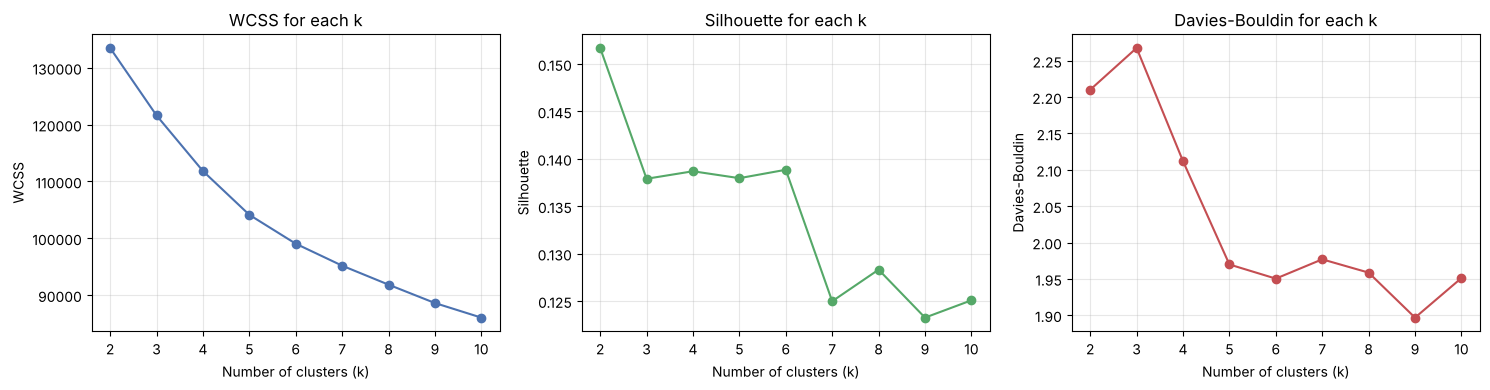

In [4]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append({
        "k": k,
        "WCSS": km.inertia_,
        "Silhouette": silhouette_score(X, km.labels_, sample_size=5000, random_state=RANDOM_STATE),
        "Davies-Bouldin": davies_bouldin_score(X, km.labels_),
    })
k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(3))
k_table.round(4).to_csv("Unsupervised_Learning/clustering_results/kmeans_k_selection.csv")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ["WCSS", "Silhouette", "Davies-Bouldin"], ["#4C72B0", "#55A868", "#C44E52"]):
    ax.plot(k_table.index, k_table[col], marker="o", color=color)
    ax.set_title(col + " for each k")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("Unsupervised_Learning/clustering_results/kmeans_k_selection.png", dpi=150, bbox_inches="tight")
plt.show()

**Interpretation.** WCSS goes down smoothly as k grows (the drop is about 11,900 from k=2 to 3, 7,700 from k=4 to 5, and 5,100 from k=5 to 6). There is no sharp elbow. The Silhouette score is low for every k, between 0.12 and 0.15. It is highest at k=2 (0.152), but this is only a little above k=3 to k=6 (about 0.138), and two groups are too few to be useful. After k=6 the Silhouette gets lower (0.125 at k=7). The Davies-Bouldin index improves a lot from k=4 (2.11) to k=5 (1.97), and then stays almost the same (1.95 for k=6). So the metrics alone do not give one clear k, and the low Silhouette tells us that the groups overlap.

#### Step 2: Check the stability
A good k should give the same groups when we change the random start. We run K-Means with three different seeds and compare each result with the first one using the Adjusted Rand Index (ARI). An ARI near 1 means the same groups.

In [5]:
stab_rows = []
for k in range(3, 8):
    labels = [KMeans(n_clusters=k, n_init=10, random_state=s).fit(X).labels_ for s in (1, 2, 3)]
    aris = [adjusted_rand_score(labels[0], l) for l in labels[1:]]
    stab_rows.append({"k": k, "ARI seed 2 vs 1": aris[0], "ARI seed 3 vs 1": aris[1]})
stability = pd.DataFrame(stab_rows).set_index("k")
display(stability.round(3))
stability.round(4).to_csv("Unsupervised_Learning/clustering_results/kmeans_stability.csv")

,ARI seed 2 vs 1,ARI seed 3 vs 1
k,,
3,0.453,0.454
4,0.999,0.999
5,0.996,0.998
6,0.665,0.666
7,0.996,0.716


**Interpretation.** K-Means gives almost the same groups for k=4 (ARI 0.999) and k=5 (ARI 0.996 and 0.998) with every seed. For k=3 (ARI about 0.45), k=6 (about 0.67) and k=7 (0.72 for one seed) the groups change when the seed changes, so these values are not reliable.

#### Step 3: Choose k and fit the final model

We choose **k = 5** for these reasons:

1. It is stable (ARI about 0.997 with different seeds).
2. Its Davies-Bouldin index (1.97) is much better than k=4 (2.11) and almost the same as k=6 (1.95), which is not stable.
3. The WCSS drops get smaller after k=5, and the Silhouette gets lower after k=6.
4. Five groups are a small number that HR managers can read and use.

The Silhouette is only about 0.14, so the groups are not sharply separated. We will treat them as overlapping segments of candidates, and we discuss this in Section 7.

In [6]:
K_FINAL = 5

kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X)
cluster_kmeans = kmeans.labels_

sizes = pd.Series(cluster_kmeans).value_counts().sort_index()
size_table = pd.DataFrame({"candidates": sizes, "share (%)": (sizes / len(X) * 100).round(1)})
size_table.index.name = "cluster"
display(size_table)

print("Silhouette (all rows):", round(silhouette_score(X, cluster_kmeans), 3))
print("Davies-Bouldin:", round(davies_bouldin_score(X, cluster_kmeans), 3))
print("WCSS:", round(kmeans.inertia_))

,candidates,share (%)
cluster,,
0,3061,16.4
1,3030,16.3
2,3464,18.6
3,5450,29.2
4,3640,19.5


Silhouette (all rows): 0.137
Davies-Bouldin: 1.97
WCSS: 104132


**Interpretation.** The five clusters have similar sizes. The smallest has 3,030 candidates (16.3%) and the largest has 5,450 candidates (29.2%), so there is no tiny cluster. The Silhouette (0.137) is low, as in Step 1, which means that the clusters overlap. The next members will profile the clusters and measure them with the second algorithm.

#### Step 4: Save the cluster labels
We add the K-Means labels to the readable cleaned data (the columns before encoding), so the next members can profile the clusters. The rows of `cleaned_data.csv` and `preprocessed_data.csv` are in the same order, and we check this before saving.

In [7]:
cleaned = pd.read_csv("Dataset/cleaned_data.csv")
assert len(cleaned) == len(X)
assert (cleaned["target"].values == y_true.values).all()  # same row order

clustered = cleaned.copy()
clustered["cluster_kmeans"] = cluster_kmeans
clustered.to_csv("Dataset/clustered_data.csv", index=False)
print("Saved Dataset/clustered_data.csv:", clustered.shape)
clustered.head()

Saved Dataset/clustered_data.csv: (18645, 14)


,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,target,cluster_kmeans
0,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,>20,Unknown,Unknown,1,36,1,3
1,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15,50-99,Pvt Ltd,>4,47,0,2
2,city_21,0.624,Unknown,No relevent experience,Full time course,Graduate,STEM,5,Unknown,Unknown,never,83,0,4
3,city_115,0.789,Unknown,No relevent experience,Unknown,Graduate,Business Degree,<1,Unknown,Pvt Ltd,never,52,1,1
4,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,>20,50-99,Funded Startup,4,8,0,2


### 3.2 Algorithm 2
*To be added by Member 3.*

## 4. Evaluation Metrics & Visualizations

*Owner: *

## 5. Cluster Interpretation & Profiles

*Owner: *

## 6. Integration Strategy (how clusters will enhance the system)

*Owner: *

## 7. Challenges & Limitations

*Owner: *